# Week 3 — Squad Optimization Engine
## Constrained Squad Selection via Integer Linear Programming

**Objective:** Given ML-predicted fair values and performance scores, select the optimal 25-player IPL squad under real auction constraints using PuLP.

**Constraints:**
- Budget: up to 120 Cr
- Squad size: 18-25 players
- Max 8 overseas players
- Minimum roles: 4 batsmen, 4 bowlers, 2 all-rounders, 2 wicketkeepers

---

In [1]:
import sys
sys.path.insert(0, '/home/claude/ipl-auction-optimizer/scripts')
from optimizer import *

PROJECT_DIR = '/home/claude/ipl-auction-optimizer'
predictions = pd.read_csv(f'{PROJECT_DIR}/data/processed/predictions.csv')
pool = prepare_player_pool(predictions, auction_year=2025)
print(f"2025 Auction Pool: {len(pool)} players")
print(f"  Indian: {(pool['player_origin']=='Indian').sum()}, Overseas: {(pool['player_origin']=='Overseas').sum()}")
print(f"  Roles: {dict(pool['role'].value_counts())}")
print(f"\nScoring ranges:")
print(f"  Performance: {pool['performance_score'].min():.1f} - {pool['performance_score'].max():.1f}")
print(f"  Value: {pool['value_score'].min():.2f} - {pool['value_score'].max():.2f}")
print(f"  Composite: {pool['composite_value'].min():.1f} - {pool['composite_value'].max():.1f}")

2025 Auction Pool: 227 players
  Indian: 159, Overseas: 68
  Roles: {'Bowler': np.int64(81), 'All-Rounder': np.int64(77), 'Batsman': np.int64(46), 'Wicketkeeper': np.int64(23)}

Scoring ranges:
  Performance: 0.0 - 89.3
  Value: 0.03 - 4.17
  Composite: 1.0 - 61.6


## Scenario 1: Best Overall Squad (Full 120 Cr Budget)
Maximise composite score (60% performance + 40% value) with all constraints.

In [2]:
r1 = optimise_squad(pool, budget=120.0, objective='composite_value')
print(format_squad(r1, 'SCENARIO 1: Best Overall Squad (120 Cr)'))

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details

  SCENARIO 1: Best Overall Squad (120 Cr)
  Players: 25 | Budget: ₹119.2/₹120 Cr | Overseas: 8/8

  Player                       Role           Origin       Price   Perf  Value
  --------------------------------------------------------------------------
  Rohit Sharma                 Batsman        Indian     ₹ 16.3   79.4   1.00
  KL Rahul                     Wicketkeeper   Indian     ₹ 14.0   77.5   0.99
  Sunil Narine                 Bowler         Overseas   ₹ 12.0   89.3   1.00
  Andre Russell                All-Rounder    Overseas   ₹ 12.0   72.9   1.01
  Ishan Kishan                 Wicketkeeper   Indian     ₹ 11.2   62.9   0.98
  Bhuvneshwar Kumar            Bowler         Overseas   ₹ 10.8   70.0   1.00
  Krunal Pandya                All-Rounder    Indian     ₹  5.8   50.5   1.00
  Glenn Maxwell             

## Scenario 2: Value Squad (80 Cr Budget)
Same objective but with a tighter budget — simulating a team that retained expensive players and has less auction purse.

In [3]:
r2 = optimise_squad(pool, budget=80.0, objective='composite_value')
print(format_squad(r2, 'SCENARIO 2: Value Squad (80 Cr Budget)'))


  SCENARIO 2: Value Squad (80 Cr Budget)
  Players: 25 | Budget: ₹79.9/₹80 Cr | Overseas: 8/8

  Player                       Role           Origin       Price   Perf  Value
  --------------------------------------------------------------------------
  Sunil Narine                 Bowler         Overseas   ₹ 12.0   89.3   1.00
  Bhuvneshwar Kumar            Bowler         Overseas   ₹ 10.8   70.0   1.00
  Krunal Pandya                All-Rounder    Indian     ₹  5.8   50.5   1.00
  Khaleel Ahmed                Bowler         Indian     ₹  4.8   44.1   1.05
  Glenn Maxwell                All-Rounder    Overseas   ₹  4.2   57.1   1.03
  Nitish Rana                  All-Rounder    Indian     ₹  4.2   40.9   1.00
  Prabhsimran Singh            Batsman        Indian     ₹  4.0   47.5   1.08
  MS Dhoni                     Wicketkeeper   Indian     ₹  4.0   61.8   1.03
  Sandeep Sharma               Bowler         Indian     ₹  4.0   69.3   1.07
  Quinton de Kock              Wicketkeeper   

## Scenario 3: Retain Stars + Build
Retain Virat Kohli and Jasprit Bumrah, then optimally fill the remaining slots.

In [4]:
r3 = optimise_squad(pool, budget=120.0, objective='composite_value', retained_players=['Virat Kohli', 'Jasprit Bumrah'])
print(format_squad(r3, 'SCENARIO 3: Retain Kohli + Bumrah + Build'))


  SCENARIO 3: Retain Kohli + Bumrah + Build
  Players: 25 | Budget: ₹119.9/₹120 Cr | Overseas: 8/8
  Retained: 2

  Player                       Role           Origin       Price   Perf  Value
  --------------------------------------------------------------------------
  Virat Kohli                  Batsman        Indian     ₹ 21.0   80.8   1.00
  Jasprit Bumrah               Bowler         Indian     ₹ 18.0   68.8   0.99
  Sunil Narine                 Bowler         Overseas   ₹ 12.0   89.3   1.00
  Andre Russell                All-Rounder    Overseas   ₹ 12.0   72.9   1.01
  Bhuvneshwar Kumar            Bowler         Overseas   ₹ 10.8   70.0   1.00
  Krunal Pandya                All-Rounder    Indian     ₹  5.8   50.5   1.00
  Glenn Maxwell                All-Rounder    Overseas   ₹  4.2   57.1   1.03
  MS Dhoni                     Wicketkeeper   Indian     ₹  4.0   61.8   1.03
  Sandeep Sharma               Bowler         Indian     ₹  4.0   69.3   1.07
  Prabhsimran Singh        

## Scenario 4: Performance-First Squad
Ignore value scores — pick the highest-performing squad regardless of price efficiency.

In [5]:
r4 = optimise_squad(pool, budget=120.0, objective='performance_score')
print(format_squad(r4, 'SCENARIO 4: Performance-First (120 Cr)'))


  SCENARIO 4: Performance-First (120 Cr)
  Players: 25 | Budget: ₹119.6/₹120 Cr | Overseas: 8/8

  Player                       Role           Origin       Price   Perf  Value
  --------------------------------------------------------------------------
  Rohit Sharma                 Batsman        Indian     ₹ 16.3   79.4   1.00
  KL Rahul                     Wicketkeeper   Indian     ₹ 14.0   77.5   0.99
  Sunil Narine                 Bowler         Overseas   ₹ 12.0   89.3   1.00
  Andre Russell                All-Rounder    Overseas   ₹ 12.0   72.9   1.01
  Bhuvneshwar Kumar            Bowler         Overseas   ₹ 10.8   70.0   1.00
  Krunal Pandya                All-Rounder    Indian     ₹  5.8   50.5   1.00
  Khaleel Ahmed                Bowler         Indian     ₹  4.8   44.1   1.05
  Nitish Rana                  All-Rounder    Indian     ₹  4.2   40.9   1.00
  Glenn Maxwell                All-Rounder    Overseas   ₹  4.2   57.1   1.03
  MS Dhoni                     Wicketkeeper 

## Scenario Comparison

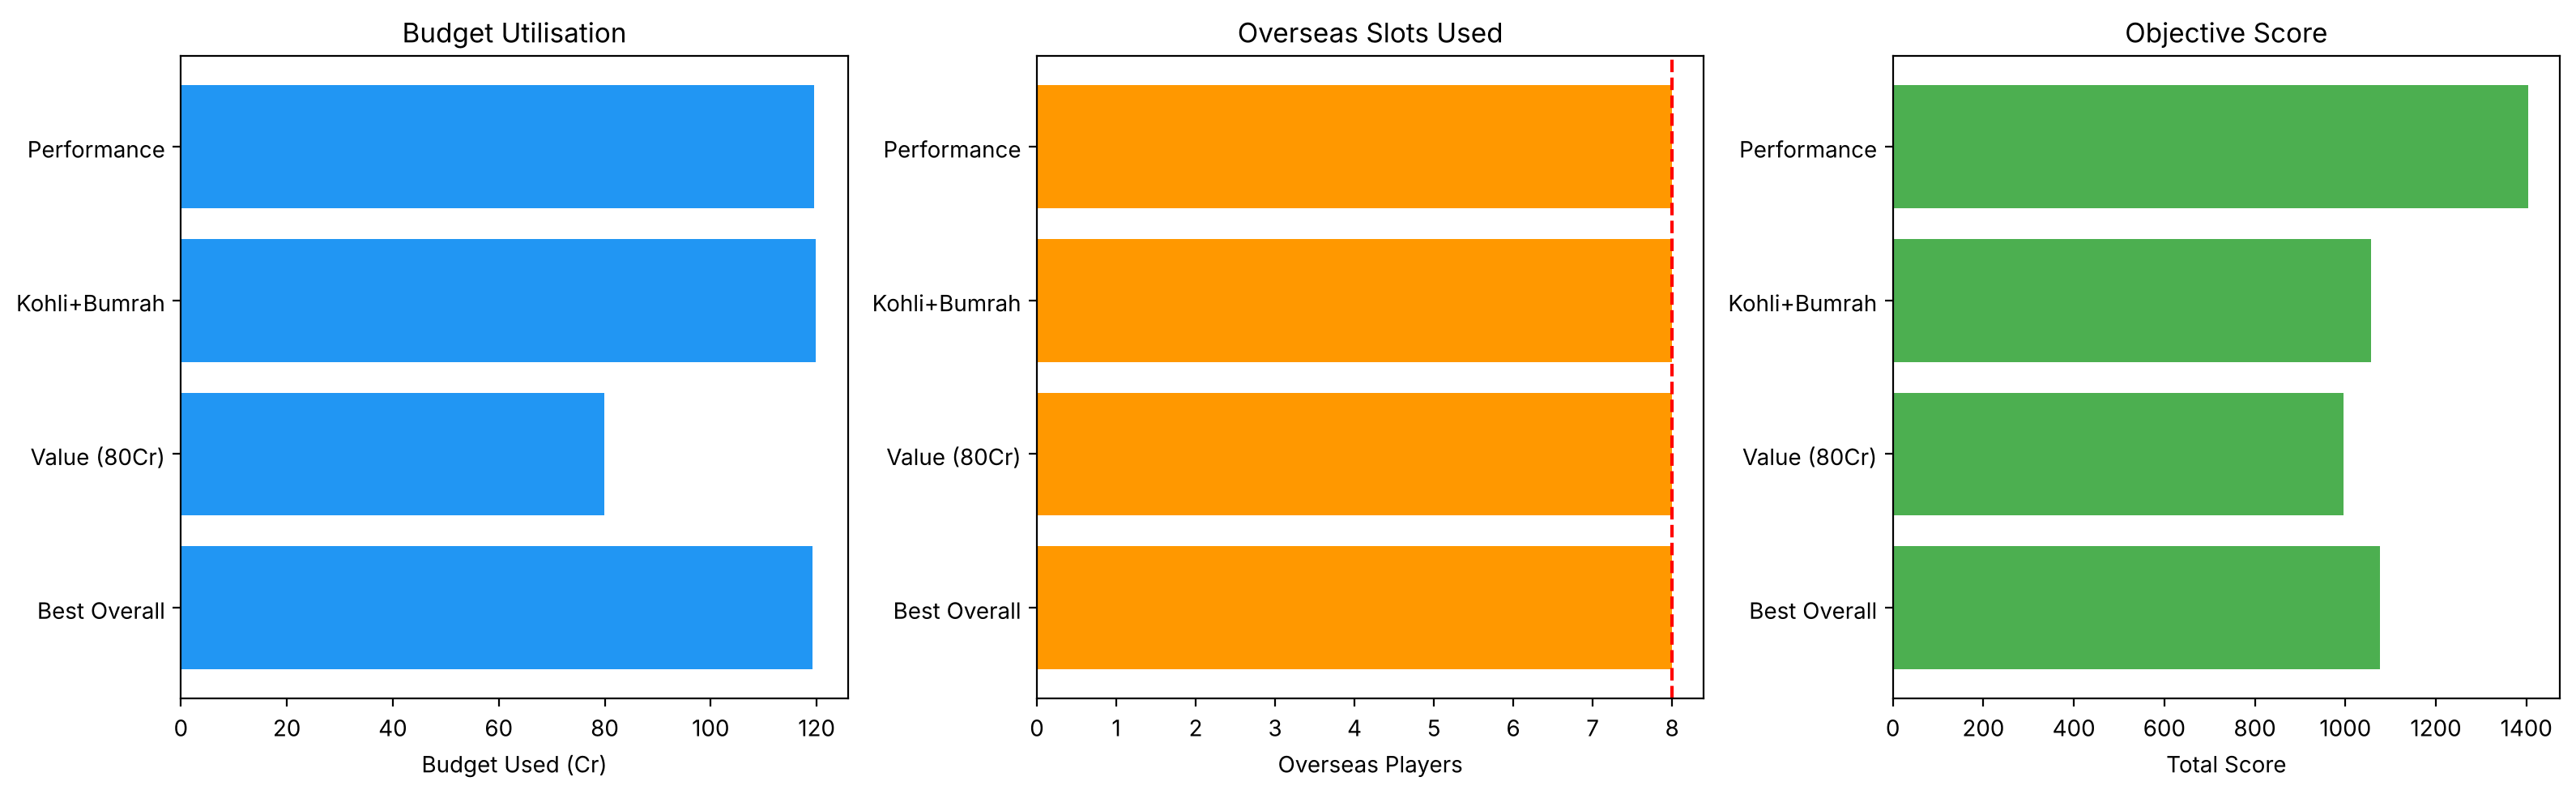

SUMMARY:
  Best Overall         | 25 players | 119.2/120 Cr | 8/8 overseas | Score: 1076
  Value (80Cr)         | 25 players | 79.9/80 Cr | 8/8 overseas | Score: 996
  Kohli+Bumrah         | 25 players | 119.9/120 Cr | 8/8 overseas | Score: 1058
  Performance          | 25 players | 119.6/120 Cr | 8/8 overseas | Score: 1404


In [6]:
import matplotlib.pyplot as plt

scenarios = {'Best Overall': r1, 'Value (80Cr)': r2, 'Kohli+Bumrah': r3, 'Performance': r4}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

names = list(scenarios.keys())
axes[0].barh(names, [s['budget_used'] for s in scenarios.values()], color='#2196F3')
axes[0].set_xlabel('Budget Used (Cr)'); axes[0].set_title('Budget Utilisation')

axes[1].barh(names, [s['overseas_count'] for s in scenarios.values()], color='#FF9800')
axes[1].set_xlabel('Overseas Players'); axes[1].set_title('Overseas Slots Used')
axes[1].axvline(8, color='red', ls='--', label='Max 8')

axes[2].barh(names, [s['total_score'] for s in scenarios.values()], color='#4CAF50')
axes[2].set_xlabel('Total Score'); axes[2].set_title('Objective Score')

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/optimizer_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("SUMMARY:")
for name, res in scenarios.items():
    sq = res['squad']
    print(f"  {name:20s} | {res['total_players']} players | {res['budget_used']:.1f}/{res['budget_used']+res['budget_remaining']:.0f} Cr | {res['overseas_count']}/8 overseas | Score: {res['total_score']:.0f}")

---
## How the Optimizer Works

### Mathematical Formulation

This is a **binary integer linear program (ILP)**:

- **Decision variables:** x_i in {0, 1} for each player i (1 = selected)
- **Objective:** Maximise SUM(x_i * score_i)
- **Subject to:**
  - SUM(x_i * price_i) <= Budget
  - SUM(x_i) <= 25 (max squad)
  - SUM(x_i) >= 18 (min squad)
  - SUM(x_i * overseas_i) <= 8
  - SUM(x_i * batsman_i) >= 4
  - SUM(x_i * bowler_i) >= 4
  - SUM(x_i * allrounder_i) >= 2
  - SUM(x_i * wk_i) >= 2

### Scoring Functions

**Performance Score (0-100):** Composite of batting (runs, SR, recent form, sixes, awards) and bowling (wickets, economy, recent form, awards), weighted by role.

**Value Score:** predicted_price / sold_price — above 1.0 means the model thinks a player is worth more than they sold for.

**Composite:** 60% performance + 40% value — balances talent with bargain hunting.

### Key Insight

The optimizer consistently uses all 8 overseas slots — overseas talent offers premium performance that justifies the slot cost. It also reveals that budget-constrained teams should prioritise bowling depth (cheaper per performance unit) and pick up undervalued veterans.